# Import Library

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Memuat Dataset (Data Understanding)

In [3]:
file_path = "data-luas-panen-dan-produksi-sayuran-dan-buah-buahan-semusim-di-provinsi-dki-jakarta-tahun-2023-komponen-data.xls"
df = pd.read_html(file_path)[0]

display(df.head())
display(df.info())

,periode_data,wilayah,jenis_sayuran_dan_buah,luas,produksi
0,2023,KAB. ADM. KEP. SERIBU,BAYAM,0.68,1.900
1,2023,KAB. ADM. KEP. SERIBU,KANGKUNG,1.70,5.260
2,2023,KAB. ADM. KEP. SERIBU,MENTIMUN,0.00,0.000
3,2023,KAB. ADM. KEP. SERIBU,PETSAI/SAWI,1.43,3.529
4,2023,KAB. ADM. KEP. SERIBU,TERONG,0.67,1.080


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 78 entries, 0 to 77
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   periode_data            78 non-null     int64  
 1   wilayah                 78 non-null     object 
 2   jenis_sayuran_dan_buah  78 non-null     object 
 3   luas                    78 non-null     float64
 4   produksi                78 non-null     float64
dtypes: float64(2), int64(1), object(2)
memory usage: 3.2+ KB


None

# Data Preparation (Pengecekan Missing Value & Outlier)

In [4]:
print("--- Pengecekan Missing Value ---")
print(df.isnull().sum())

print("\n--- Deskripsi Statistik ---")
display(df.describe())

--- Pengecekan Missing Value ---
periode_data              0
wilayah                   0
jenis_sayuran_dan_buah    0
luas                      0
produksi                  0
dtype: int64

--- Deskripsi Statistik ---


,periode_data,luas,produksi
count,78.0,78.000000,78.000000
mean,2023.0,17.568974,115.309821
std,0.0,58.547265,452.003759
min,2023.0,0.000000,0.000000
25%,2023.0,0.000000,0.000000
50%,2023.0,0.000000,0.000000
75%,2023.0,1.687500,3.279000
max,2023.0,324.210000,2590.200000


# Penentuan Variabel (X dan y)

In [5]:
# X = Variabel Independen (Luas Lahan)
# y = Variabel Dependen (Produksi)
X = df[['luas']]
y = df['produksi']

# Pembagian Data (Train & Test Split)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Jumlah data latih: {len(X_train)}")
print(f"Jumlah data uji: {len(X_test)}")

Jumlah data latih: 62
Jumlah data uji: 16


# Pemodelan Regresi Linier

In [7]:
model = LinearRegression()
model.fit(X_train, y_train)

b = model.coef_[0]
a = model.intercept_
print(f"Persamaan Regresi Linier: y = {a:.2f} + {b:.2f}X")
print(f"Konstanta (a) : {a:.2f}")
print(f"Koefisien (b) : {b:.2f}")

Persamaan Regresi Linier: y = -26.31 + 7.24X
Konstanta (a) : -26.31
Koefisien (b) : 7.24


# Prediksi & Evaluasi Model

In [8]:
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("--- Evaluasi Performa Model ---")
print(f"R-squared (R2)           : {r2:.4f}")
print(f"Mean Squared Error (MSE) : {mse:.2f}")
print(f"Root Mean Squared Error  : {rmse:.2f}")

--- Evaluasi Performa Model ---
R-squared (R2)           : 0.6329
Mean Squared Error (MSE) : 35305.56
Root Mean Squared Error  : 187.90


# Visualisasi Hasil Regresi

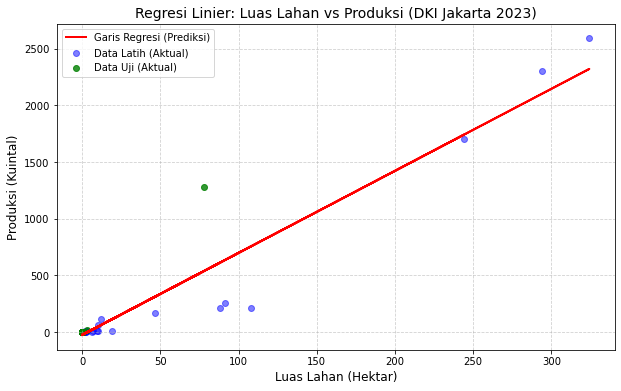

In [9]:
plt.figure(figsize=(10, 6))

plt.scatter(X_train, y_train, color='blue', alpha=0.5, label='Data Latih (Aktual)')
plt.scatter(X_test, y_test, color='green', alpha=0.8, label='Data Uji (Aktual)')
plt.plot(X, model.predict(X), color='red', linewidth=2, label='Garis Regresi (Prediksi)')

plt.title('Regresi Linier: Luas Lahan vs Produksi (DKI Jakarta 2023)', fontsize=14)
plt.xlabel('Luas Lahan (Hektar)', fontsize=12)
plt.ylabel('Produksi (Kuintal)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()